# Experiment 4 — Unsupervised Learning I: Clustering Techniques

## Setup — Imports and Configuration

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import cdist, pdist
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.datasets import make_moons
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             adjusted_rand_score)

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------
SEED = 42
CSV_PATH = "Mall_Customers.csv"
FEATURES = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
K_RANGE = range(2, 11)          # k = 2 ... 10
DUNN_SUBSAMPLE = 1000           # pairwise-distance metrics: max points used (fixed subsample)
FIG_DIR = "exp4_figures"
os.makedirs(FIG_DIR, exist_ok=True)


def banner(text):
    print("\n" + "=" * 70)
    print(text)
    print("=" * 70)


def save_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150)
    plt.show()
    plt.close(fig)

## Helper Functions
K-Medoids, knee finder, k-distance, Dunn index, evaluation function and plotting helpers.

In [7]:
# ----------------------------------------------------------------------
# HELPER FUNCTIONS
# ----------------------------------------------------------------------
def kmedoids(X, k, seed=SEED, max_iter=100):
    """Simple K-Medoids (alternating / Voronoi iteration).
    Centre = an actual data point, so it is robust to outliers."""
    rng = np.random.RandomState(seed)
    n = X.shape[0]
    D = cdist(X, X)                               # full distance matrix (n x n)
    medoids = [rng.randint(n)]                    # k-medoids++ style initialisation
    for _ in range(1, k):
        d2 = D[:, medoids].min(axis=1) ** 2
        medoids.append(rng.choice(n, p=d2 / d2.sum()))
    medoids = np.array(medoids)
    for _ in range(max_iter):
        labels = D[:, medoids].argmin(axis=1)     # assignment step
        new_medoids = medoids.copy()
        for j in range(k):                        # update step
            members = np.where(labels == j)[0]
            if len(members) == 0:
                continue
            within = D[np.ix_(members, members)].sum(axis=1)
            new_medoids[j] = members[within.argmin()]
        if np.array_equal(new_medoids, medoids):
            break
        medoids = new_medoids
    labels = D[:, medoids].argmin(axis=1)
    return labels, medoids


def knee_point(y, decreasing=False):
    """Knee/elbow = point farthest from the straight line joining first and last
    point of the (normalised) curve."""
    y = np.asarray(y, dtype=float)
    xn = np.linspace(0, 1, len(y))
    yn = (y - y.min()) / (y.max() - y.min())
    gap = (1 - xn) - yn if decreasing else xn - yn
    return int(gap.argmax())


def k_distance(X, min_samples):
    """Sorted distance of every point to its min_samples-th neighbour
    (the point itself counts as neighbour 1, same as DBSCAN's min_samples)."""
    nn = NearestNeighbors(n_neighbors=min_samples).fit(X)
    dist, _ = nn.kneighbors(X)
    return np.sort(dist[:, -1])


def dunn_index(X, labels):
    """Dunn = (minimum distance between points of two DIFFERENT clusters)
              / (maximum distance between two points of the SAME cluster).
    Higher is better. Undefined (nan) if <2 clusters or the denominator is 0."""
    ids = np.unique(labels)
    if len(ids) < 2:
        return np.nan
    groups = [X[labels == c] for c in ids]
    max_diam = 0.0
    for g in groups:
        if len(g) > 1:
            max_diam = max(max_diam, pdist(g).max())
    if max_diam == 0:
        return np.nan
    min_sep = np.inf
    for a in range(len(groups)):
        for b in range(a + 1, len(groups)):
            min_sep = min(min_sep, cdist(groups[a], groups[b]).min())
    return min_sep / max_diam


def fixed_subsample_idx(n, cap=DUNN_SUBSAMPLE, seed=SEED):
    """Same indices every run. If n <= cap, all points are used."""
    if n <= cap:
        return np.arange(n)
    return np.sort(np.random.RandomState(seed).choice(n, cap, replace=False))


def evaluate(X, labels):
    """WCSS, Silhouette, Davies-Bouldin, Dunn (+ clusters, coverage).
    Noise (-1) is excluded. Undefined scores -> nan (printed as N/A)."""
    mask = labels != -1
    Xv, lv = X[mask], labels[mask]
    ids = np.unique(lv)
    out = {"Clusters": len(ids), "Coverage%": 100.0 * mask.sum() / len(labels),
           "WCSS": np.nan, "Silhouette": np.nan, "Davies-Bouldin": np.nan,
           "Dunn": np.nan}
    if len(ids) == 0:
        return out
    wcss = 0.0                                     # about the cluster mean (same rule for all)
    for c in ids:
        pts = Xv[lv == c]
        wcss += ((pts - pts.mean(axis=0)) ** 2).sum()
    out["WCSS"] = wcss
    if len(ids) < 2:                               # fewer than 2 valid clusters
        return out
    cents = np.array([Xv[lv == c].mean(axis=0) for c in ids])
    if pdist(cents).min() > 0:                     # DB denominator must not be 0
        out["Davies-Bouldin"] = davies_bouldin_score(Xv, lv)
    idx = fixed_subsample_idx(len(Xv))             # quadratic metrics on fixed subsample
    Xs, ls = Xv[idx], lv[idx]
    n_sub_clusters = len(np.unique(ls))
    if 2 <= n_sub_clusters <= len(ls) - 1:
        out["Silhouette"] = silhouette_score(Xs, ls)
    out["Dunn"] = dunn_index(Xs, ls)
    return out


def fmt(v, digits=3):
    return "N/A" if (v is None or (isinstance(v, float) and np.isnan(v))) else f"{v:.{digits}f}"


def scatter_clusters(ax, Z, labels, title):
    for c in np.unique(labels):
        m = labels == c
        if c == -1:
            ax.scatter(Z[m, 0], Z[m, 1], c="black", marker="x", s=25, label="noise")
        else:
            ax.scatter(Z[m, 0], Z[m, 1], s=25, color=plt.cm.tab10(c % 10), label=f"C{c}")
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(fontsize=7)

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Load Data
CustomerID and Gender are dropped; Age, Annual Income and Spending Score are used.

In [6]:
# LOAD DATA
if not os.path.exists('/content/drive/MyDrive/Mall_Customers.csv'):
    try:                                           # in Google Colab an upload button appears
        from google.colab import files
        CSV_PATH = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError("Place Mall_Customers.csv in the same folder as this script")

df = pd.read_csv('/content/drive/MyDrive/Mall_Customers.csv')
banner("DATASET INFO")
print("Shape  :", df.shape)
print("Columns:", list(df.columns))
print("Missing values:", int(df.isnull().sum().sum()))
print("CustomerID and Gender are dropped (the ID carries no meaning and a binary"
      " Gender column distorts distances).")
X_raw = df[FEATURES].values.astype(float)
n_samples, n_features = X_raw.shape


DATASET INFO
Shape  : (200, 5)
Columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Missing values: 0
CustomerID and Gender are dropped (the ID carries no meaning and a binary Gender column distorts distances).


## Task 1 — Standardisation
Standardise the features and explain why this matters more for clustering than for trees.


TASK 1 : STANDARDISATION
Before scaling (raw):
        Age  Annual Income (k$)  Spending Score (1-100)
mean  38.85               60.56                   50.20
std   13.97               26.26                   25.82
min   18.00               15.00                    1.00
max   70.00              137.00                   99.00

After scaling (z-score):
       Age  Annual Income (k$)  Spending Score (1-100)
mean -0.00               -0.00                   -0.00
std   1.00                1.00                    1.00
min  -1.50               -1.74                   -1.91
max   2.24                2.92                    1.89

K-Means (k=5) on RAW vs SCALED data:
  Adjusted Rand Index between the two partitions = 0.602 (1.0 would mean scaling changed nothing)
  Cluster sizes raw   : [23 79 39 36 23]
  Cluster sizes scaled: [20 54 40 39 47]

WHY SCALING MATTERS MORE FOR CLUSTERING THAN FOR TREES:
 - K-Means, K-Medoids, hierarchical clustering and DBSCAN all depend on DISTANCES.
   A feature 

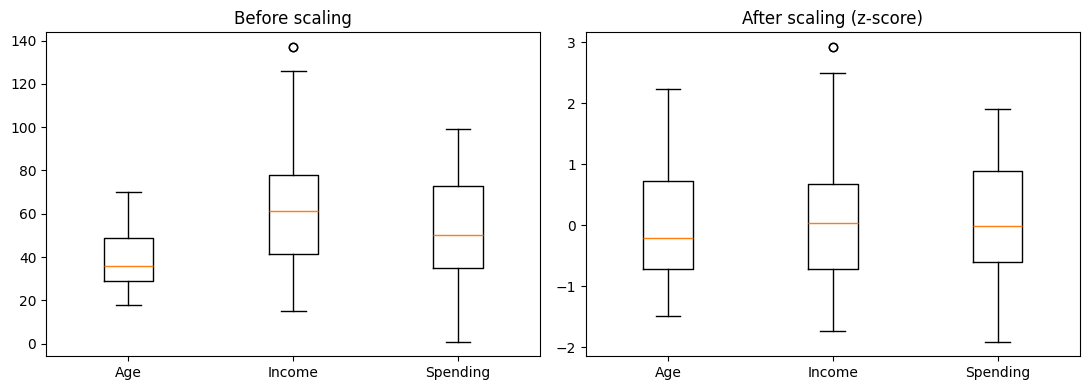

In [8]:
# TASK 1 : STANDARDISE THE FEATURES
banner("TASK 1 : STANDARDISATION")
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

print("Before scaling (raw):")
print(pd.DataFrame(X_raw, columns=FEATURES).describe().loc[["mean", "std", "min", "max"]].round(2))
print("\nAfter scaling (z-score):")
print(pd.DataFrame(X, columns=FEATURES).describe().loc[["mean", "std", "min", "max"]].round(2))

# effect of scaling on a clustering result (k = 5 just for demonstration)
km_raw = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=SEED).fit(X_raw)
km_scl = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=SEED).fit(X)
print("\nK-Means (k=5) on RAW vs SCALED data:")
print("  Adjusted Rand Index between the two partitions =",
      round(adjusted_rand_score(km_raw.labels_, km_scl.labels_), 3),
      "(1.0 would mean scaling changed nothing)")
print("  Cluster sizes raw   :", np.bincount(km_raw.labels_))
print("  Cluster sizes scaled:", np.bincount(km_scl.labels_))

print("""
WHY SCALING MATTERS MORE FOR CLUSTERING THAN FOR TREES:
 - K-Means, K-Medoids, hierarchical clustering and DBSCAN all depend on DISTANCES.
   A feature with a larger range/spread (Income 15-137, Age 18-70, Spending 1-99)
   influences the distance more, so on raw data the cluster structure is distorted.
 - A decision tree splits on one feature at a time with a threshold (x_j <= t).
   A monotonic rescaling of a feature does not change the ordering of the splits,
   so trees are scale-invariant.
 - Hence skipping scaling makes "distance" misleading in clustering, while it does
   no harm to trees.""")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].boxplot(X_raw)
ax[0].set_xticklabels(["Age", "Income", "Spending"])
ax[0].set_title("Before scaling")
ax[1].boxplot(X)
ax[1].set_xticklabels(["Age", "Income", "Spending"])
ax[1].set_title("After scaling (z-score)")
save_show(fig, "task1_scaling.png")

## Task 2 — K-Means, Elbow and Silhouette
Run K-Means for k = 2…10; plot the elbow (WCSS) and the silhouette score and pick k.


TASK 2 : K-MEANS, ELBOW AND SILHOUETTE
  k       WCSS  Silhouette
  2     389.39      0.3355
  3     295.21      0.3578
  4     205.23      0.4040
  5     168.25      0.4166
  6     133.87      0.4284
  7     117.01      0.4172
  8     103.87      0.4082
  9      93.09      0.4177
 10      82.39      0.4066

Elbow suggests k = 4
Best silhouette at k = 6  (score = 0.4284)
CHOSEN k = 6  (highest silhouette; cross-checked against the elbow)


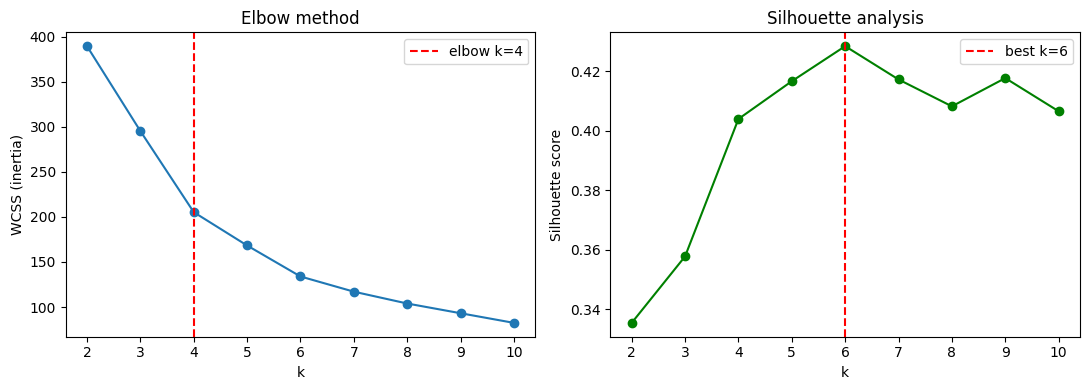

In [9]:
# TASK 2 : K-MEANS FOR k = 2..10 (ELBOW + SILHOUETTE)
banner("TASK 2 : K-MEANS, ELBOW AND SILHOUETTE")
k_list, wcss_list, sil_list = [], [], []
print(f"{'k':>3} {'WCSS':>10} {'Silhouette':>11}")
for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(X)
    k_list.append(k)
    wcss_list.append(km.inertia_)
    sil_list.append(silhouette_score(X, km.labels_))
    print(f"{k:>3} {km.inertia_:>10.2f} {sil_list[-1]:>11.4f}")

k_elbow = k_list[knee_point(wcss_list, decreasing=True)]
k_sil = k_list[int(np.argmax(sil_list))]
K_CHOSEN = k_sil
print(f"\nElbow suggests k = {k_elbow}")
print(f"Best silhouette at k = {k_sil}  (score = {max(sil_list):.4f})")
print(f"CHOSEN k = {K_CHOSEN}  (highest silhouette; cross-checked against the elbow)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_list, wcss_list, "o-")
ax[0].axvline(k_elbow, color="red", ls="--", label=f"elbow k={k_elbow}")
ax[0].set_xlabel("k")
ax[0].set_ylabel("WCSS (inertia)")
ax[0].set_title("Elbow method")
ax[0].legend()
ax[1].plot(k_list, sil_list, "o-", color="green")
ax[1].axvline(k_sil, color="red", ls="--", label=f"best k={k_sil}")
ax[1].set_xlabel("k")
ax[1].set_ylabel("Silhouette score")
ax[1].set_title("Silhouette analysis")
ax[1].legend()
save_show(fig, "task2_elbow_silhouette.png")

kmeans = KMeans(n_clusters=K_CHOSEN, init="k-means++", n_init=10, random_state=SEED).fit(X)
labels_km = kmeans.labels_

## Task 3 — K-Medoids vs K-Means
Run K-Medoids at the same k and compare the cluster centres.

In [10]:
# TASK 3 : K-MEDOIDS (SAME k) AND COMPARE CENTRES
banner("TASK 3 : K-MEDOIDS vs K-MEANS CENTRES")
labels_kmed, medoid_idx = kmedoids(X, K_CHOSEN, seed=SEED)

cent_km = kmeans.cluster_centers_                  # means (not real data points)
cent_med = X[medoid_idx]                           # real data points
cost = cdist(cent_km, cent_med)                    # match each centroid to nearest medoid
row, col = linear_sum_assignment(cost)

cols = ["Age", "Income", "Spending"]
rows_out = []
for r, c in zip(row, col):
    cen_orig = scaler.inverse_transform(cent_km[r].reshape(1, -1))[0]
    med_orig = scaler.inverse_transform(cent_med[c].reshape(1, -1))[0]
    rows_out.append([f"KM-{r}", *cen_orig.round(1), f"KMed-{c}", *med_orig.round(1),
                     round(cost[r, c], 3), int(df.loc[medoid_idx[c], "CustomerID"])])
cmp_df = pd.DataFrame(rows_out, columns=["KMeans", *[f"c_{x}" for x in cols],
                                         "KMedoids", *[f"m_{x}" for x in cols],
                                         "dist(scaled)", "Medoid CustomerID"])
print("Centres in ORIGINAL units (c_ = K-Means centroid, m_ = K-Medoids medoid):")
print(cmp_df.to_string(index=False))
print("\nAdjusted Rand Index (K-Means vs K-Medoids labels) =",
      round(adjusted_rand_score(labels_km, labels_kmed), 3))
print("K-Means sizes  :", np.bincount(labels_km))
print("K-Medoids sizes:", np.bincount(labels_kmed))
print("""
NOTE: Centroid = mean of the cluster (not a real customer; pulled by outliers).
      Medoid   = an actual customer (data point), so it is robust to outliers.
      When clusters are tight and outliers are few, the two centres are very close.""")


TASK 3 : K-MEDOIDS vs K-MEANS CENTRES
Centres in ORIGINAL units (c_ = K-Means centroid, m_ = K-Medoids medoid):
KMeans  c_Age  c_Income  c_Spending KMedoids  m_Age  m_Income  m_Spending  dist(scaled)  Medoid CustomerID
  KM-0   56.3      54.3        49.1   KMed-0   63.0      48.0        51.0         0.540                 65
  KM-1   26.8      57.1        48.1   KMed-4   23.0      54.0        52.0         0.333                 79
  KM-2   41.9      88.9        17.0   KMed-3   42.0      86.0        20.0         0.163                167
  KM-3   32.7      86.5        82.1   KMed-1   30.0      88.0        86.0         0.251                176
  KM-4   25.0      25.3        77.6   KMed-2   25.0      24.0        73.0         0.185                 22
  KM-5   45.5      26.3        19.4   KMed-5   47.0      49.0        42.0         1.239                 72

Adjusted Rand Index (K-Means vs K-Medoids labels) = 0.708
K-Means sizes  : [45 39 33 39 23 21]
K-Medoids sizes: [24 39 25 35 32 45]

NOTE

## Task 4 — Agglomerative Clustering (single / complete / average)
Plot the three dendrograms and describe how the linkage changes the result.


TASK 4 : AGGLOMERATIVE CLUSTERING AND DENDROGRAMS
Single   : cluster sizes = [  2   2 193   1   1   1], cophenetic corr = 0.542, final merge height = 1.08
Complete : cluster sizes = [39 35 57 21 32 16], cophenetic corr = 0.593, final merge height = 5.99
Average  : cluster sizes = [39 52  4 31 54 20], cophenetic corr = 0.668, final merge height = 2.72


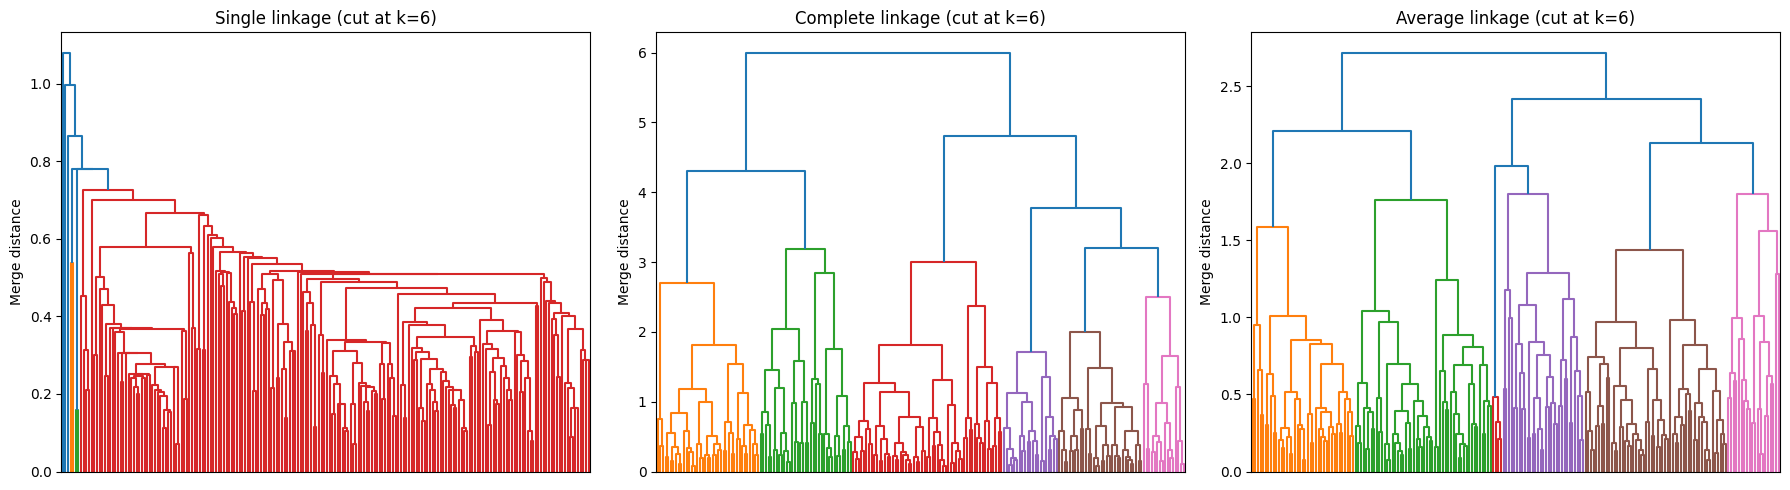


HOW LINKAGE CHANGES THE RESULT:
 - SINGLE  : nearest-pair distance. Shows the "chaining" effect: one huge cluster
             plus a few tiny or single-point clusters, staircase-like dendrogram.
 - COMPLETE: farthest-pair distance. Gives compact clusters of similar size.
 - AVERAGE : a compromise between the two; less chaining and less outlier-sensitive.
 Cutting the dendrogram across its largest vertical gap is a way to choose k.


In [11]:
# TASK 4 : AGGLOMERATIVE (SINGLE / COMPLETE / AVERAGE) + DENDROGRAMS
banner("TASK 4 : AGGLOMERATIVE CLUSTERING AND DENDROGRAMS")
agglo_labels = {}
pair_d = pdist(X)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, method in zip(axes, ["single", "complete", "average"]):
    Z = linkage(X, method=method)
    lab = fcluster(Z, t=K_CHOSEN, criterion="maxclust") - 1
    agglo_labels[method] = lab
    coph = cophenet(Z, pair_d)[0]
    dendrogram(Z, ax=ax, no_labels=True, color_threshold=Z[-(K_CHOSEN - 1), 2])
    ax.set_title(f"{method.capitalize()} linkage (cut at k={K_CHOSEN})")
    ax.set_ylabel("Merge distance")
    print(f"{method.capitalize():<9}: cluster sizes = {np.bincount(lab)}, "
          f"cophenetic corr = {coph:.3f}, final merge height = {Z[-1, 2]:.2f}")
save_show(fig, "task4_dendrograms.png")
print("""
HOW LINKAGE CHANGES THE RESULT:
 - SINGLE  : nearest-pair distance. Shows the "chaining" effect: one huge cluster
             plus a few tiny or single-point clusters, staircase-like dendrogram.
 - COMPLETE: farthest-pair distance. Gives compact clusters of similar size.
 - AVERAGE : a compromise between the two; less chaining and less outlier-sensitive.
 Cutting the dendrogram across its largest vertical gap is a way to choose k.""")

## Task 5 — DBSCAN
Select eps from the k-distance plot and report how many points are noise.


TASK 5 : DBSCAN
min_samples = 6  (2 x number of features)
automatic knee estimate = 0.786  (too large here: merges everything into 1 cluster)
eps chosen from the k-distance plot = 0.55
Clusters found : 5
Noise points   : 55 of 200 (27.5%)
  noise     : 55 points
  cluster 0 : 19 points
  cluster 1 : 54 points
  cluster 2 : 29 points
  cluster 3 : 33 points
  cluster 4 : 10 points


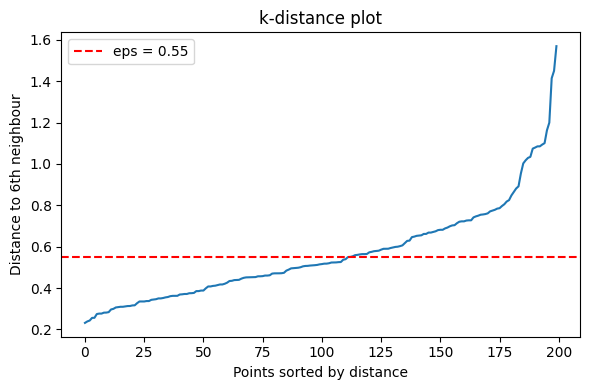

(eps is sensitive: slightly smaller gives more noise and tiny clusters, slightly larger merges clusters. So eps was chosen near the bend of the plot and the result was checked.)


In [12]:
# TASK 5 : DBSCAN WITH k-DISTANCE PLOT
banner("TASK 5 : DBSCAN")
MIN_SAMPLES = 2 * n_features                       # rule of thumb: 2 x dimensions
kd = k_distance(X, MIN_SAMPLES)
EPS_KNEE = float(kd[knee_point(kd, decreasing=False)])   # automatic estimate (reference only)
EPS = 0.55          # eps chosen near the bend of the k-distance plot (adjust after inspecting the plot)
print(f"min_samples = {MIN_SAMPLES}  (2 x number of features)")
print(f"automatic knee estimate = {EPS_KNEE:.3f}  (too large here: merges everything into 1 cluster)")
print(f"eps chosen from the k-distance plot = {EPS}")

db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X)
labels_db = db.labels_
n_noise = int((labels_db == -1).sum())
n_db_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
print(f"Clusters found : {n_db_clusters}")
print(f"Noise points   : {n_noise} of {n_samples} ({100 * n_noise / n_samples:.1f}%)")
for c in sorted(set(labels_db)):
    name = "noise" if c == -1 else f"cluster {c}"
    print(f"  {name:<10}: {int((labels_db == c).sum())} points")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(kd)
ax.axhline(EPS, color="red", ls="--", label=f"eps = {EPS:.2f}")
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel(f"Distance to {MIN_SAMPLES}th neighbour")
ax.set_title("k-distance plot")
ax.legend()
save_show(fig, "task5_kdistance.png")
print("(eps is sensitive: slightly smaller gives more noise and tiny clusters, slightly larger merges"
      " clusters. So eps was chosen near the bend of the plot and the result was checked.)")

## Task 6 — PCA (2D) Visualisation
Reduce to two dimensions with PCA and plot the clusters produced by each algorithm.


TASK 6 : PCA 2D VISUALISATION
Explained variance ratio: [0.443 0.333] | total = 0.776


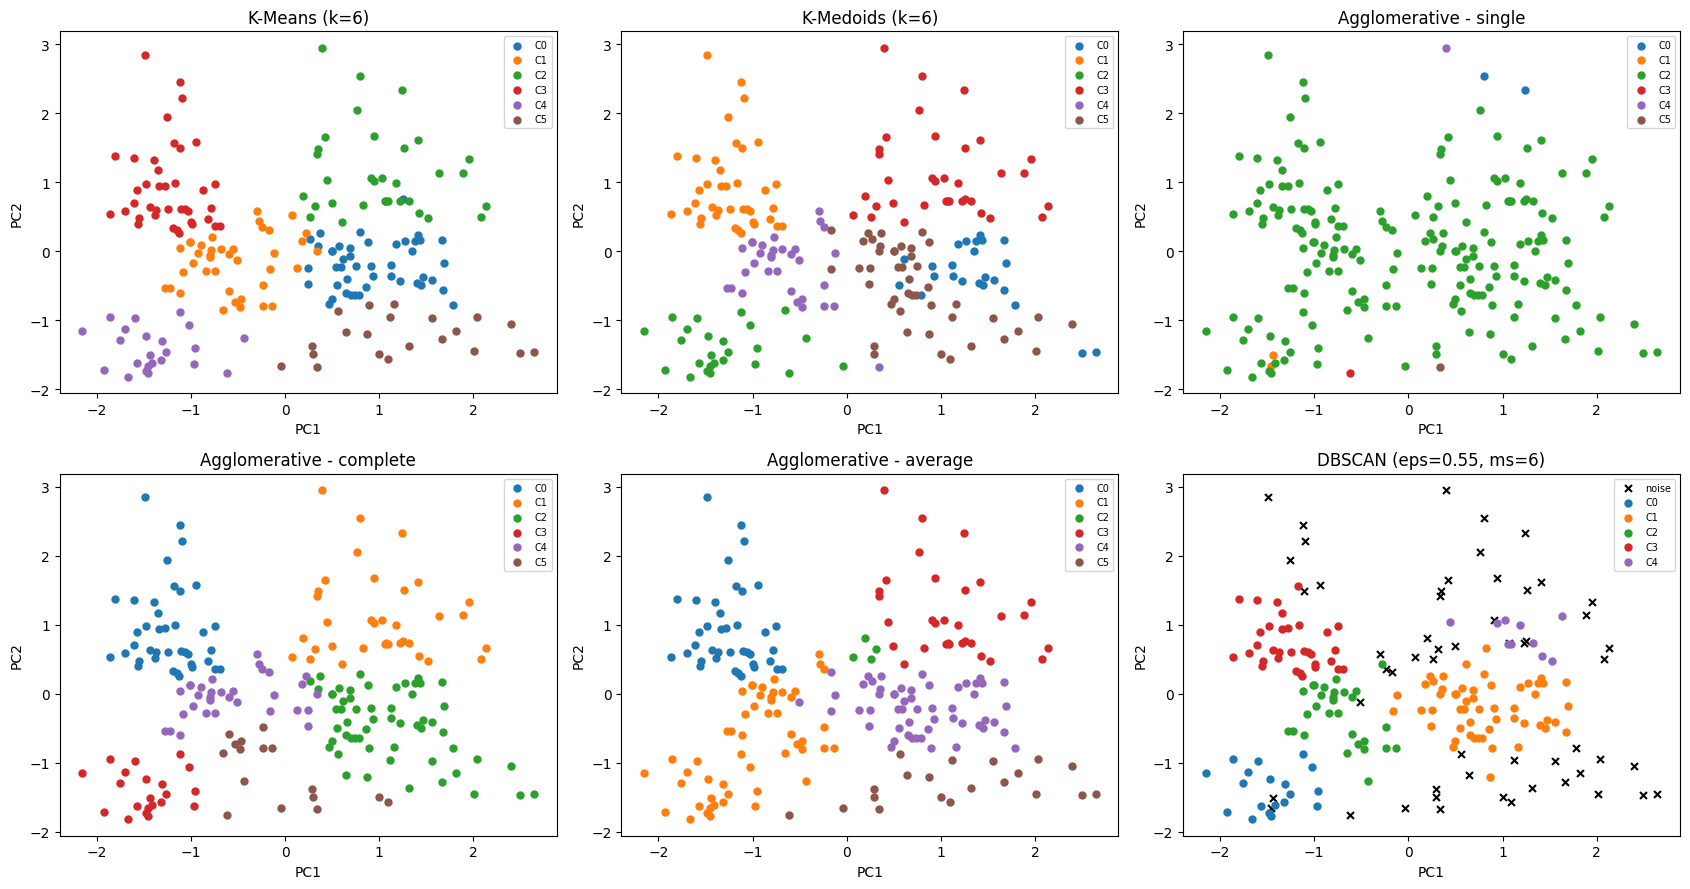

In [13]:
# TASK 6 : PCA TO 2D AND PLOT EVERY ALGORITHM
banner("TASK 6 : PCA 2D VISUALISATION")
pca = PCA(n_components=2, random_state=SEED)
Z2 = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| total =", round(pca.explained_variance_ratio_.sum(), 3))

all_labels = {
    f"K-Means (k={K_CHOSEN})": labels_km,
    f"K-Medoids (k={K_CHOSEN})": labels_kmed,
    "Agglomerative - single": agglo_labels["single"],
    "Agglomerative - complete": agglo_labels["complete"],
    "Agglomerative - average": agglo_labels["average"],
    f"DBSCAN (eps={EPS:.2f}, ms={MIN_SAMPLES})": labels_db,
}
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (name, lab) in zip(axes.ravel(), all_labels.items()):
    scatter_clusters(ax, Z2, lab, name)
save_show(fig, "task6_pca_clusters.png")

## Task 7 — Evaluation Table
Tabulate WCSS, silhouette, Davies–Bouldin and Dunn.
DBSCAN: noise excluded, retained coverage reported, undefined scores shown as N/A, exact Dunn definition stated, fixed subsample for pairwise-distance metrics.

In [14]:
# TASK 7 : METRICS TABLE
banner("TASK 7 : EVALUATION TABLE")
results = []
for name, lab in all_labels.items():
    r = evaluate(X, lab)
    results.append([name, r["Clusters"], r["Coverage%"], r["WCSS"], r["Silhouette"],
                    r["Davies-Bouldin"], r["Dunn"]])
res_df = pd.DataFrame(results, columns=["Algorithm", "Clusters", "Coverage%", "WCSS",
                                        "Silhouette", "Davies-Bouldin", "Dunn"])

print(f"{'Algorithm':<34}{'Clus':>5}{'Cover%':>8}{'WCSS':>10}{'Silh':>8}{'DB':>8}{'Dunn':>8}")
for _, r in res_df.iterrows():
    print(f"{r['Algorithm']:<34}{int(r['Clusters']):>5}{r['Coverage%']:>8.1f}"
          f"{fmt(r['WCSS'], 2):>10}{fmt(r['Silhouette']):>8}"
          f"{fmt(r['Davies-Bouldin']):>8}{fmt(r['Dunn']):>8}")
res_df.to_csv(os.path.join(FIG_DIR, "task7_metrics.csv"), index=False)

print(f"""
NOTES FOR THE REPORT:
 - Direction : WCSS lower better | Silhouette higher better (-1..1)
               Davies-Bouldin lower better | Dunn higher better.
 - WCSS is computed the same way for all algorithms: sum of squared distances of
   points to their own cluster MEAN, on the standardised data.
 - DUNN DEFINITION: Dunn = d_min / d_max, where
     d_min = smallest distance between two points that belong to DIFFERENT clusters
     d_max = largest distance between two points inside the SAME cluster
             (largest cluster diameter over all clusters).
 - DBSCAN: noise points (-1) are EXCLUDED from every score. Coverage% = fraction of
   points retained (non-noise), so scores must be read together with coverage.
 - N/A is printed when fewer than 2 valid clusters remain or a denominator is zero.
 - Silhouette and Dunn need all pairwise distances (quadratic), so a FIXED random
   subsample (seed={SEED}, max {DUNN_SUBSAMPLE} points) is used; with n={n_samples}
   <= {DUNN_SUBSAMPLE} every point is used.""")


TASK 7 : EVALUATION TABLE
Algorithm                          Clus  Cover%      WCSS    Silh      DB    Dunn
K-Means (k=6)                         6   100.0    133.87   0.428   0.825   0.062
K-Medoids (k=6)                       6   100.0    147.39   0.379   0.943   0.059
Agglomerative - single                6   100.0    550.68  -0.043   0.637   0.130
Agglomerative - complete              6   100.0    157.07   0.375   1.000   0.105
Agglomerative - average               6   100.0    165.30   0.390   0.865   0.122
DBSCAN (eps=0.55, ms=6)               5    72.5     66.20   0.484   0.686   0.168

NOTES FOR THE REPORT:
 - Direction : WCSS lower better | Silhouette higher better (-1..1)
               Davies-Bouldin lower better | Dunn higher better.
 - WCSS is computed the same way for all algorithms: sum of squared distances of
   points to their own cluster MEAN, on the standardised data.
 - DUNN DEFINITION: Dunn = d_min / d_max, where
     d_min = smallest distance between two points t

## Task 8 — make_moons: K-Means vs DBSCAN
Repeat K-Means and DBSCAN on make_moons and explain the difference in the result.


TASK 8 : make_moons - K-MEANS vs DBSCAN
DBSCAN on moons: min_samples = 5, eps = 0.2 (k-distance 98th percentile = 0.188)


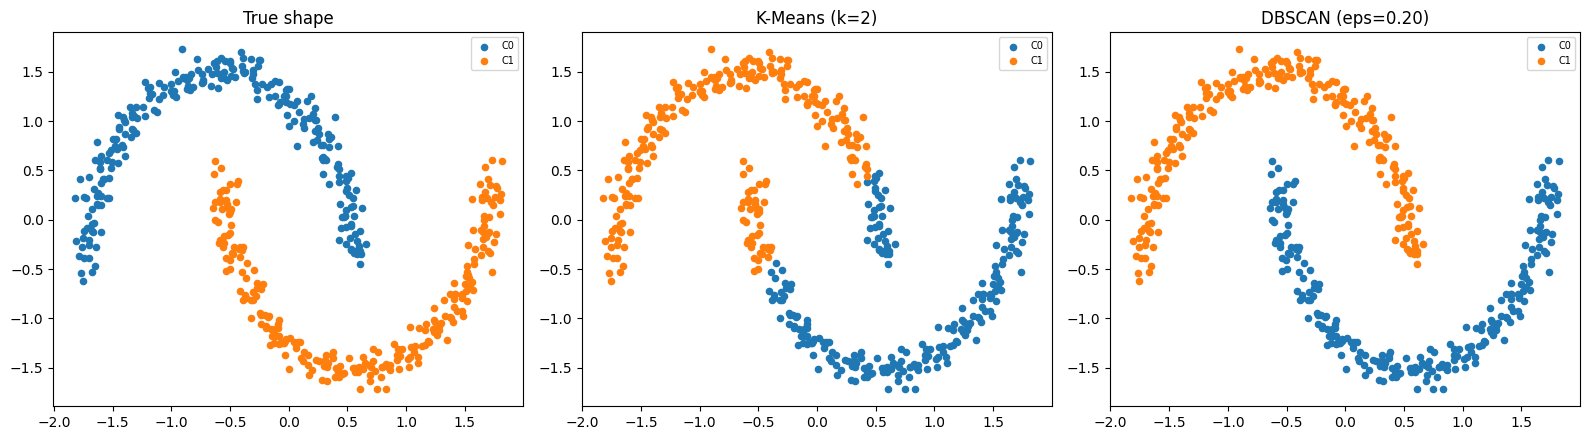


Method             ARI vs truth Clusters  Cover%    Silh      DB    Dunn
K-Means (k=2)             0.445        2   100.0   0.496   0.811   0.023
DBSCAN                    1.000        2   100.0   0.389   1.018   0.223

EXPLANATION:
 - K-Means is centroid-based and assumes spherical / convex clusters. It cuts the two
   crescent-shaped moons with a straight boundary, so parts of the two moons get
   mixed together and the ARI is low.
 - DBSCAN links density-connected points, so it can follow arbitrary (curved) shapes
   and labels sparse points as noise.
 - Note: silhouette and Davies-Bouldin favour convex clusters, so K-Means can score
   well on them even though its clusters are wrong. The ground-truth ARI shows the
   real picture.


In [15]:
# TASK 8 : K-MEANS vs DBSCAN ON make_moons
banner("TASK 8 : make_moons - K-MEANS vs DBSCAN")
Xm_raw, ym = make_moons(n_samples=500, noise=0.05, random_state=SEED)
Xm = StandardScaler().fit_transform(Xm_raw)

km_m = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=SEED).fit(Xm)
MIN_S_M = 5
kd_m = k_distance(Xm, MIN_S_M)
EPS_M = 0.2         # near the bend of the moons k-distance plot
db_m = DBSCAN(eps=EPS_M, min_samples=MIN_S_M).fit(Xm)
print(f"DBSCAN on moons: min_samples = {MIN_S_M}, eps = {EPS_M} "
      f"(k-distance 98th percentile = {np.percentile(kd_m, 98):.3f})")

moon_sets = [("True shape", ym), ("K-Means (k=2)", km_m.labels_),
             (f"DBSCAN (eps={EPS_M:.2f})", db_m.labels_)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, lab) in zip(axes, moon_sets):
    for c in np.unique(lab):
        m = lab == c
        if c == -1:
            ax.scatter(Xm[m, 0], Xm[m, 1], c="black", marker="x", s=25, label="noise")
        else:
            ax.scatter(Xm[m, 0], Xm[m, 1], s=20, color=plt.cm.tab10(c % 10), label=f"C{c}")
    ax.set_title(name)
    ax.legend(fontsize=7)
save_show(fig, "task8_moons.png")

print(f"\n{'Method':<18}{'ARI vs truth':>13}{'Clusters':>9}{'Cover%':>8}{'Silh':>8}{'DB':>8}{'Dunn':>8}")
for name, lab in [("K-Means (k=2)", km_m.labels_), ("DBSCAN", db_m.labels_)]:
    r = evaluate(Xm, lab)
    mask = lab != -1
    ari = adjusted_rand_score(ym[mask], lab[mask])
    print(f"{name:<18}{ari:>13.3f}{r['Clusters']:>9}{r['Coverage%']:>8.1f}"
          f"{fmt(r['Silhouette']):>8}{fmt(r['Davies-Bouldin']):>8}{fmt(r['Dunn']):>8}")

print("""
EXPLANATION:
 - K-Means is centroid-based and assumes spherical / convex clusters. It cuts the two
   crescent-shaped moons with a straight boundary, so parts of the two moons get
   mixed together and the ARI is low.
 - DBSCAN links density-connected points, so it can follow arbitrary (curved) shapes
   and labels sparse points as noise.
 - Note: silhouette and Davies-Bouldin favour convex clusters, so K-Means can score
   well on them even though its clusters are wrong. The ground-truth ARI shows the
   real picture.""")

In [16]:
import shutil
print("Figures saved in:", FIG_DIR, "->", sorted(os.listdir(FIG_DIR)))
shutil.make_archive("exp4_outputs", "zip", FIG_DIR)
try:
    from google.colab import files
    files.download("exp4_outputs.zip")
except ImportError:
    print("Not running in Colab: exp4_outputs.zip is in the current folder.")

Figures saved in: exp4_figures -> ['task1_scaling.png', 'task2_elbow_silhouette.png', 'task4_dendrograms.png', 'task5_kdistance.png', 'task6_pca_clusters.png', 'task7_metrics.csv', 'task8_moons.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>